# First real lap: Bahrain 2023 qualifying

Question: where does Verstappen gain or lose time relative to Pérez?

Source: **OpenF1 contributors**, https://openf1.org/, **CC BY-NC-SA 4.0**.
These are real historical telemetry samples, not synthetic data. The selected
API snapshots are bundled with retrieval metadata and SHA-256 hashes in datasets/openf1/.
This noncommercial derived notebook is shared under the same licence.

Run using this repository's virtual environment. Distance is integrated from speed;
continuous lap-edge samples are interpolated only when bracketed. Throttle is clipped
to 0–100% and discrete brake/gear use previous-sample hold. See the README for limitations.

In [1]:
from pathlib import Path
import os
# Support launching Jupyter from either the repository root or notebooks/.
if Path.cwd().name == 'notebooks':
    os.chdir('..')
import matplotlib.pyplot as plt
from IPython.display import display
from f1_analyser.data import load_session, eligible_laps, fastest_pair, lap_telemetry, lap_summary
from f1_analyser.analysis import compare_laps, braking_windows, corner_metrics
from f1_analyser.plots import telemetry_figure
session = load_session(2023, 'Bahrain', 'Q')
display(eligible_laps(session)[['Driver', 'LapNumber', 'LapTime', 'Segment', 'Compound', 'TyreLife']])

,Driver,LapNumber,LapTime,Segment,Compound,TyreLife
0,TSU,2,0 days 00:01:32.132000,Q1,SOFT,1
1,DEV,2,0 days 00:01:32.849000,Q1,SOFT,1
2,LEC,2,0 days 00:02:11.454000,Q1,MEDIUM,1
3,ALB,2,0 days 00:01:32.094000,Q1,SOFT,1
4,ZHO,2,0 days 00:01:31.947000,Q1,SOFT,1
...,...,...,...,...,...,...
148,VER,14,0 days 00:01:29.708000,Q3,SOFT,1
149,PER,14,0 days 00:01:29.846000,Q3,SOFT,1
150,SAI,17,0 days 00:01:30.154000,Q3,SOFT,1
151,VER,15,0 days 00:01:58.862000,Q3,SOFT,2


{'driver': 'VER',
 'lap_number': 14,
 'lap_seconds': 89.708,
 'lap_start_session_seconds': 4045.801,
 'sector_1_seconds': 28.736,
 'sector_2_seconds': 38.514,
 'sector_3_seconds': 22.458,
 'compound': 'SOFT',
 'tyre_life': 1.0,
 'fresh_tyre': None}

,Distance,Time,Speed,Throttle,Brake,nGear
0,0.000000,0.000,292.825,100.0,0.0,7.0
1,20.772437,0.254,296.000,100.0,0.0,8.0
2,47.254937,0.575,298.000,100.0,0.0,8.0
3,80.588271,0.975,302.000,100.0,0.0,8.0
4,114.310493,1.375,305.000,100.0,0.0,8.0


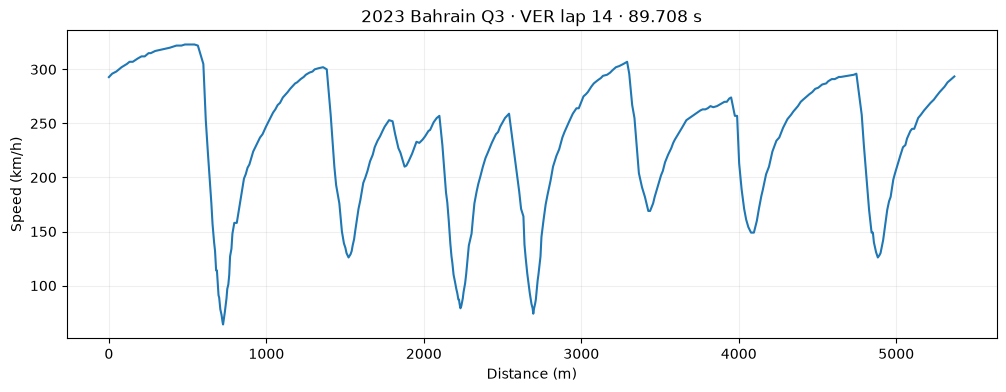

In [2]:
reference, comparison = fastest_pair(session, 'VER', 'PER', 'Q3')
ta, tb = lap_telemetry(reference), lap_telemetry(comparison)
display(lap_summary(reference))
display(ta.head())
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ta.Distance, ta.Speed, color='tab:blue')
ax.set(xlabel='Distance (m)', ylabel='Speed (km/h)',
       title=f"2023 Bahrain Q3 · VER lap {int(reference.LapNumber)} · {reference.LapTime.total_seconds():.3f} s")
ax.grid(alpha=0.2)
Path('reports/generated').mkdir(parents=True, exist_ok=True)
fig.savefig('reports/generated/bahrain-first-lap.png', dpi=160, bbox_inches='tight')
plt.show()

## Compare a fair pair

These are each driver's fastest eligible Q3 laps on a common dry compound. Inspect tyre age and weather before interpreting the difference. Equal compound and segment do not control setup, fuel, traffic or track evolution.

In [3]:
display(lap_summary(comparison))
result = compare_laps(ta, tb, reference.LapTime.total_seconds(), comparison.LapTime.total_seconds())
print(f'Recorded PER − VER: {result.recorded_gap:+.3f} s')
print(f'Estimated: {result.estimated_gap:+.3f} s; discrepancy: {result.discrepancy:+.3f} s')
print(f'Distance overlap: {result.coverage:.2%}; warnings: {result.warnings}')
windows = braking_windows(ta)
telemetry_figure(result, 'VER', 'PER', windows).show()

{'driver': 'PER',
 'lap_number': 14,
 'lap_seconds': 89.846,
 'lap_start_session_seconds': 4051.988,
 'sector_1_seconds': 28.723,
 'sector_2_seconds': 38.537,
 'sector_3_seconds': 22.586,
 'compound': 'SOFT',
 'tyre_life': 1.0,
 'fresh_tyre': None}

Recorded PER − VER: +0.138 s
Estimated: +0.087 s; discrepancy: -0.051 s
Distance overlap: 99.89%; warnings: []


In [4]:
for number, (start, end) in enumerate(windows, 1):
    print(f'Section {number}: {start:.0f}–{end:.0f} m (proposal; inspect manually)')
    display({'VER': corner_metrics(ta, start, end), 'PER': corner_metrics(tb, start, end)})
assert abs(compare_laps(ta, ta, reference.LapTime.total_seconds(), reference.LapTime.total_seconds()).estimated_gap) < 1e-9
reverse = compare_laps(tb, ta, comparison.LapTime.total_seconds(), reference.LapTime.total_seconds())
assert abs(reverse.estimated_gap + result.estimated_gap) < 1e-9

Section 1: 500–1000 m (proposal; inspect manually)


{'VER': {'braking_onset_m': 599.8542430555556,
  'minimum_speed_kmh': 64.0,
  'minimum_speed_m': 725.114798611111,
  'high_throttle_return_m': 769.5814652777777,
  'high_throttle_seconds': 3.7589999999999995,
  'observed_start_m': 500.4542430555556,
  'observed_end_m': 997.4781319444446},
 'PER': {'braking_onset_m': 583.1052132523149,
  'minimum_speed_kmh': 70.0,
  'minimum_speed_m': 736.7804910300928,
  'high_throttle_return_m': 814.3999354745374,
  'high_throttle_seconds': 4.08,
  'observed_start_m': 507.53410214120373,
  'observed_end_m': 980.1327132523154}}

Section 2: 1284–1784 m (proposal; inspect manually)


{'VER': {'braking_onset_m': 1383.6146597222225,
  'minimum_speed_kmh': 126.0,
  'minimum_speed_m': 1521.9479930555556,
  'high_throttle_return_m': 1585.1535486111115,
  'high_throttle_seconds': 4.600999999999999,
  'observed_start_m': 1293.3093819444446,
  'observed_end_m': 1779.1522986111113},
 'PER': {'braking_onset_m': 1395.3460465856488,
  'minimum_speed_kmh': 123.0,
  'minimum_speed_m': 1524.9738243634265,
  'high_throttle_return_m': 1579.7738243634267,
  'high_throttle_seconds': 4.440999999999999,
  'observed_start_m': 1291.2563243634268,
  'observed_end_m': 1768.3879910300934}}

Section 3: 2018–2518 m (proposal; inspect manually)


{'VER': {'braking_onset_m': 2117.7624374999996,
  'minimum_speed_kmh': 79.0,
  'minimum_speed_m': 2232.5013263888886,
  'high_throttle_return_m': 2285.6779930555554,
  'high_throttle_seconds': 5.282000000000004,
  'observed_start_m': 2029.1866041666665,
  'observed_end_m': 2515.486048611112},
 'PER': {'braking_onset_m': 2130.4799354745383,
  'minimum_speed_kmh': 79.0,
  'minimum_speed_m': 2244.2132688078705,
  'high_throttle_return_m': 2292.368824363426,
  'high_throttle_seconds': 5.519999999999996,
  'observed_start_m': 2019.2491021412047,
  'observed_end_m': 2515.2846576967595}}

## Write three findings

After manually checking the sections, use reports/CASE_STUDY_GUIDE.md. Describe the observation, measurement, uncertainty and possible confounders. Brake status is binary, not brake pressure. Run `python scripts/analyse_sessions.py --all` for the planned three-session validation. Do not claim completion until those runs succeed.